# Cov-LL1: covariance images

Some imaging systems measure, at each pixel, how several signals vary together: a
**covariance matrix** of size K × K. The **Cov-LL1** model writes such an image as a sum
of terms *non-negative spatial map × covariance matrix*
(see [Cov-LL1](../models/covll1.md)). Each pixel's matrix is stored as a vector of K²
numbers, so the data form a tensor of shape (rows, columns, K²).

## The data

20 × 20 pixels with 2 × 2 covariance matrices (K² = 4 numbers per pixel). There are
R = 2 terms with spatial maps of rank L1 = 5 and covariance matrices of rank L2 = 2.
{meth}`~pybbtd.covll1.CovLL1.generate_covll1_tensor` draws random non-negative spatial
factors and random covariance matrices.

In [1]:
import numpy as np

from pybbtd import CovLL1
from pybbtd.covll1 import is_valid_covariance, validate_covariance_tensor
from pybbtd.visualization import plot_error

np.random.seed(0)
model = CovLL1((20, 20, 4), R=2, L1=5, L2=2)
(A0, B0, C0), T = model.generate_covll1_tensor()
T.shape

(20, 20, 4)

Every pixel holds a valid covariance matrix (Hermitian and positive semidefinite):

In [2]:
validate_covariance_tensor(T)

True

## Fit the model

The AO-ADMM solver keeps the spatial maps non-negative and every covariance matrix
positive semidefinite. A K-means initialization groups pixels with similar covariance
matrices to get a starting point.

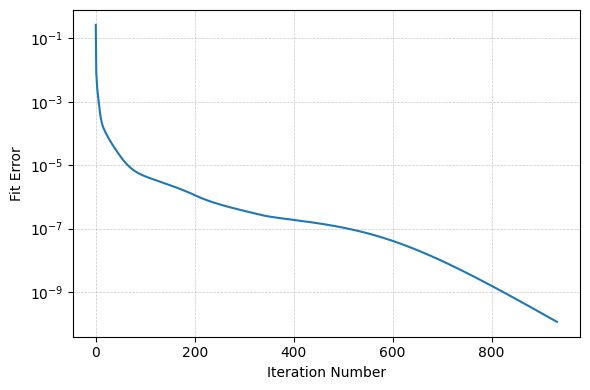

In [3]:
model.fit(T, init="kmeans", max_iter=10000, max_admm=50, rel_tol=1e-6, abs_tol=1e-12)
plot_error(model.fit_error)

## Check the result

The covariance matrix of each term, true and recovered, scaled so that its largest entry
has magnitude 1. The order of the terms can differ.

In [4]:
np.set_printoptions(precision=3, suppress=True)
A, B, C = model.factors
for name, factor in [("true", C0), ("recovered", C)]:
    print(name)
    for r in range(model.rank):
        Sigma = factor[:, r].reshape(2, 2)
        print(Sigma / np.abs(Sigma).max())

true
[[ 0.495+0.j    -0.194-0.233j]
 [-0.194+0.233j  1.   +0.j   ]]
[[1.   +0.j    0.299-0.047j]
 [0.299+0.047j 0.344+0.j   ]]
recovered
[[ 0.495+0.j    -0.194-0.233j]
 [-0.194+0.233j  1.   +0.j   ]]
[[1.   +0.j    0.299-0.047j]
 [0.299+0.047j 0.344+0.j   ]]


The constraints hold and the relative error is small:

In [5]:
print("A, B non-negative:", A.min() >= 0, B.min() >= 0)
print(
    "valid covariances:", [is_valid_covariance(c.reshape(2, 2), tol=1e-8) for c in C.T]
)
print("relative error:", np.linalg.norm(model.tensor - T) / np.linalg.norm(T))

A, B non-negative: True True
valid covariances: [True, True]
relative error: 1.0730008964911908e-05


Cov-LL1 does not constrain the rank L2 of the covariance matrices; the fourth-order
[BBTD model](bbtd-admm.ipynb) does.